# Credit Card Fraud Detection — EDA & Modeling

Dataset: [Credit Card Fraud Detection (ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) on Kaggle.

284,807 transactions, 492 fraud (0.172%). Features V1-V28 are PCA components (anonymized for privacy).
This notebook covers: EDA, imbalance handling, model comparison, and picking a final model.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('../src')

sns.set_style('whitegrid')
%matplotlib inline

## 1. Load the data

Download `creditcard.csv` from Kaggle and place it in `data/` before running this cell.

In [19]:
df = pd.read_csv('../data/creditcard.csv')
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Class imbalance — the headline chart

This is the first thing to show in your README/portfolio writeup — it sets up why this project is harder than a typical classification task.

Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.173%


/var/folders/xb/yg9jly_54jzdpwqqhyr3z3tc0000gn/T/ipykernel_10104/1824959220.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Legit (0)', 'Fraud (1)'])


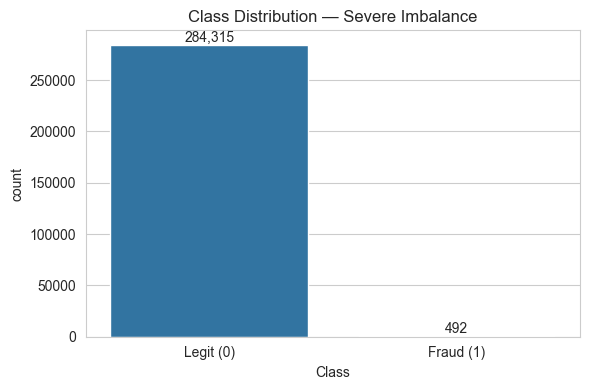

In [20]:
fraud_counts = df['Class'].value_counts()
print(fraud_counts)
print(f"Fraud rate: {df['Class'].mean()*100:.3f}%")

fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(x='Class', data=df, ax=ax)
ax.set_xticklabels(['Legit (0)', 'Fraud (1)'])
ax.set_title('Class Distribution — Severe Imbalance')
for i, v in enumerate(fraud_counts):
    ax.text(i, v + 3000, f'{v:,}', ha='center')
plt.tight_layout()
plt.savefig('../models/class_distribution.png', dpi=120)
plt.show()

## 3. Amount distribution

`Amount` is heavily right-skewed — most transactions are small, with a long tail of large ones. Worth log-transforming for visualization.

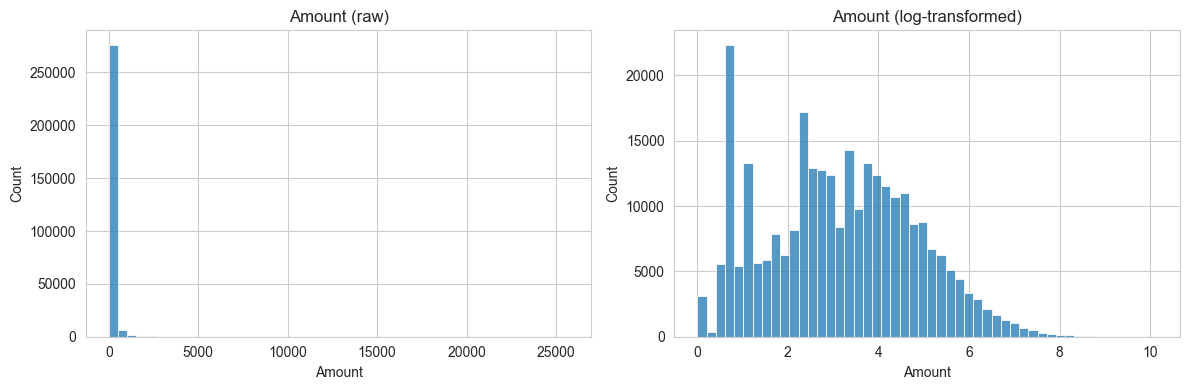

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df['Amount'], bins=50, ax=axes[0])
axes[0].set_title('Amount (raw)')

sns.histplot(np.log1p(df['Amount']), bins=50, ax=axes[1])
axes[1].set_title('Amount (log-transformed)')
plt.tight_layout()

plt.show()

print(df.groupby('Class')['Amount'].describe())

## 4. Correlation of V1–V28 with Class

Since these are PCA components, we can't name them meaningfully, but we can see which ones separate fraud best.

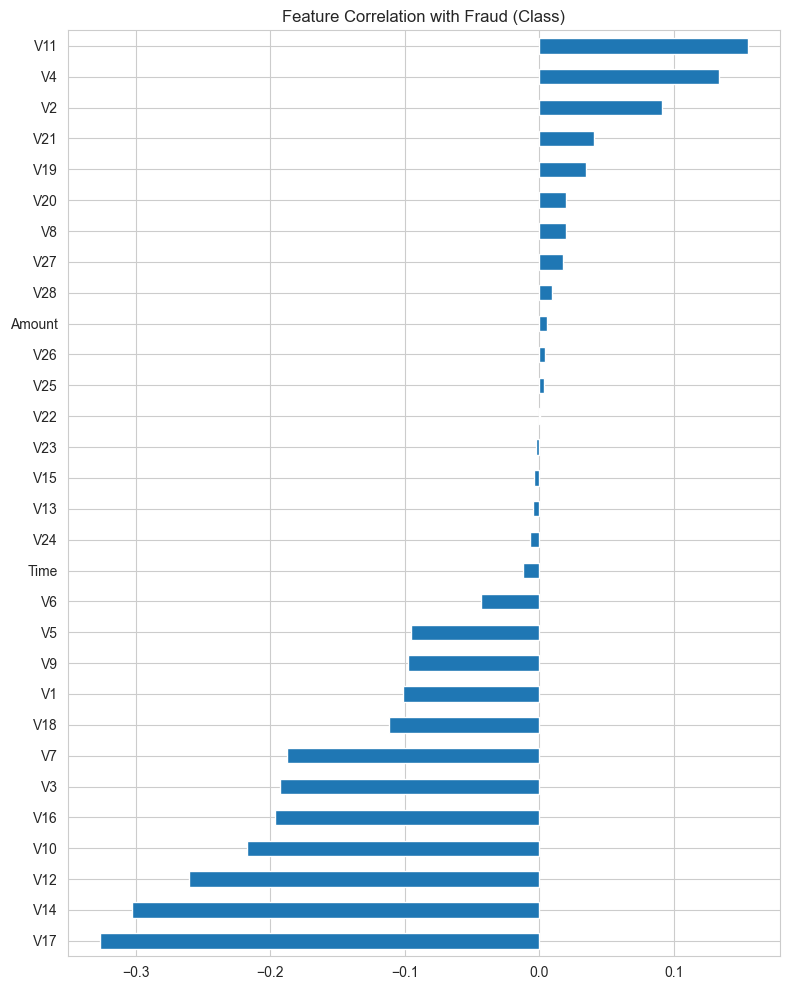

Strongest negative correlations: ['V17', 'V14', 'V12', 'V10', 'V16']
Strongest positive correlations: ['V19', 'V21', 'V2', 'V4', 'V11']


In [22]:
corr = df.corr()['Class'].drop('Class').sort_values()

fig, ax = plt.subplots(figsize=(8,10))
corr.plot(kind='barh', ax=ax)
ax.set_title('Feature Correlation with Fraud (Class)')
plt.tight_layout()
plt.show()

print("Strongest negative correlations:", corr.head(5).index.tolist())
print("Strongest positive correlations:", corr.tail(5).index.tolist())

## 5. Time-based pattern check

`Time` is seconds elapsed since the first transaction in the dataset (spans ~2 days). Worth checking if fraud clusters at certain points.

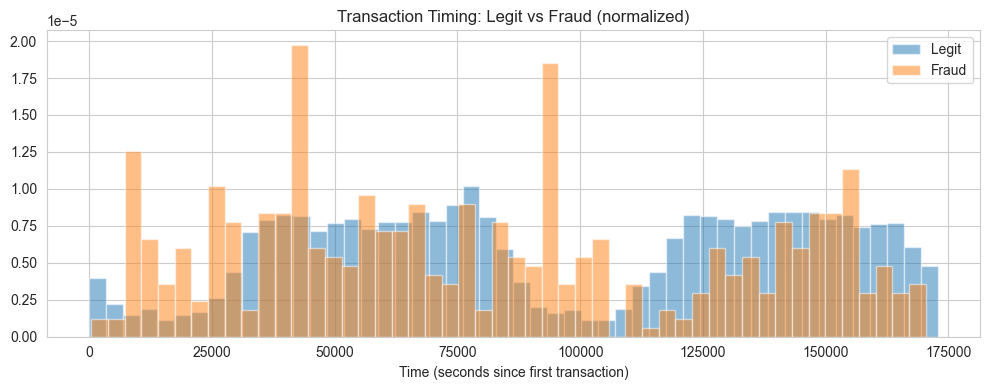

In [23]:
fig, ax = plt.subplots(figsize=(10,4))
df[df['Class']==0]['Time'].hist(bins=50, alpha=0.5, label='Legit', density=True, ax=ax)
df[df['Class']==1]['Time'].hist(bins=50, alpha=0.5, label='Fraud', density=True, ax=ax)
ax.set_xlabel('Time (seconds since first transaction)')
ax.legend()
ax.set_title('Transaction Timing: Legit vs Fraud (normalized)')
plt.tight_layout()
plt.show()

## 6. Preprocessing: scale + stratified split

In [24]:
from preprocess import scale_features, split_data

df_scaled = scale_features(df)
X_train, X_test, y_train, y_test = split_data(df_scaled)

print(f"Train: {X_train.shape}, fraud rate {y_train.mean()*100:.3f}%")
print(f"Test:  {X_test.shape}, fraud rate {y_test.mean()*100:.3f}%")

Train: (227845, 30), fraud rate 0.173%
Test:  (56962, 30), fraud rate 0.172%


## 7. Handling imbalance — two approaches, compared

**Approach A: class weighting** — tell the model to penalize missing fraud more heavily. No synthetic data, works with any sklearn-style model.

**Approach B: SMOTE** — generate synthetic fraud examples by interpolating between real ones, to balance the training set.

Important: SMOTE is applied to the TRAINING set ONLY. Applying it before the split (or to the test set) leaks synthetic patterns into evaluation and gives you fake, inflated scores — a common beginner mistake worth explicitly avoiding and mentioning in your writeup.

In [25]:
from preprocess import balance_with_smote

X_train_smote, y_train_smote = balance_with_smote(X_train, y_train)

After SMOTE: {0: 227451, 1: 227451}


## 8. Train three models (class-weighted version)

In [26]:
from train import train_logistic_regression, train_random_forest, train_xgboost
from evaluate import evaluate_model

results = {}

print("=== Logistic Regression ===")
lr = train_logistic_regression(X_train, y_train)
results['Logistic Regression'] = evaluate_model(lr, X_test, y_test)

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/rajendrans/Documents/My Projects/Ai Powered Fraud Detection System/venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <6749C431-FD87-3912-A7CF-11CB9194D072> /Users/rajendrans/Documents/My Projects/Ai Powered Fraud Detection System/venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib

In [27]:
print("=== Random Forest ===")
rf = train_random_forest(X_train, y_train)
results['Random Forest'] = evaluate_model(rf, X_test, y_test)

=== Random Forest ===


NameError: name 'train_random_forest' is not defined

In [28]:
print("=== XGBoost ===")
xgb = train_xgboost(X_train, y_train)
results['XGBoost'] = evaluate_model(xgb, X_test, y_test)

=== XGBoost ===


NameError: name 'train_xgboost' is not defined

## 9. (Optional comparison) Same models trained on SMOTE-balanced data

Train XGBoost on the SMOTE set too, and compare — a nice "I tested two imbalance strategies and here's what I found" talking point for your README.

In [29]:
fraud_ratio_smote = (y_train_smote == 0).sum() / (y_train_smote == 1).sum()  # will be ~1.0
from xgboost import XGBClassifier

xgb_smote = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.1,
    eval_metric='aucpr', random_state=42, n_jobs=-1
)
xgb_smote.fit(X_train_smote, y_train_smote)

print("=== XGBoost (SMOTE-balanced training data) ===")
results['XGBoost + SMOTE'] = evaluate_model(xgb_smote, X_test, y_test)

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/rajendrans/Documents/My Projects/Ai Powered Fraud Detection System/venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <6749C431-FD87-3912-A7CF-11CB9194D072> /Users/rajendrans/Documents/My Projects/Ai Powered Fraud Detection System/venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib

## 10. Compare all models — Precision-Recall curves

PR-AUC (not ROC-AUC) is the metric to lead with on imbalanced data like this.

NameError: name 'lr' is not defined

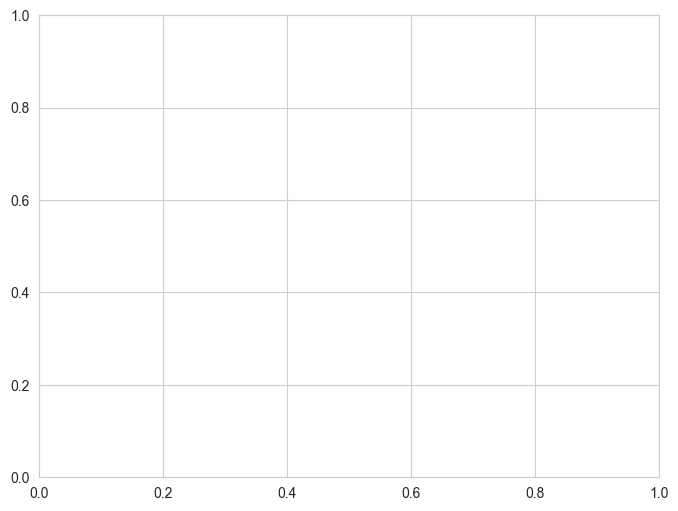

In [30]:
from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(figsize=(8,6))
models = {'Logistic Regression': lr, 'Random Forest': rf, 'XGBoost': xgb, 'XGBoost + SMOTE': xgb_smote}

for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    ax.plot(recall, precision, label=f"{name} (PR-AUC={results[name]['pr_auc']:.3f})")

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves — Model Comparison')
ax.legend()
plt.tight_layout()
plt.savefig('../models/pr_curves.png', dpi=120)
plt.show()

## 11. Results summary & final model choice

Build the comparison table, then pick a final model. For fraud detection, a missed fraud (false negative) is usually more costly than a false alarm (false positive) — so when scores are close, lean toward the model with higher recall, and say so explicitly in your writeup.

In [33]:
results_df = pd.DataFrame(results).T
results_df = results_df[['precision', 'recall', 'f1', 'roc_auc', 'pr_auc']]
results_df.round(4)

NameError: name 'results' is not defined

In [35]:
# Pick final model — adjust this line if your priorities differ
best_model_name = results_df['pr_auc'].idxmax()
print(f"Best model by PR-AUC: {best_model_name}")

best_model = models[best_model_name]

NameError: name 'results_df' is not defined

## 12. Save the final model for the Streamlit app

In [36]:
import joblib

joblib.dump(best_model, '../models/fraud_model.pkl')
print("Saved to models/fraud_model.pkl")

NameError: name 'best_model' is not defined

## Next steps

- Open `STEPS.md` at the project root if you want the full beginner walkthrough (environment setup → running this notebook → running the app → deploying).
- Run `streamlit run ../app.py` from the project root to launch the interactive demo.
- Optional stretch goal: add SHAP explanations so the app can say *why* a transaction was flagged.